## Importazioni

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, lil_matrix, identity, kron
from scipy.sparse.linalg import spsolve
from scipy.sparse import identity
from scipy.sparse import eye
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye
from scipy.sparse.linalg import spsolve

# Failed attempts and experimentation

## First Failed attempt

### failed attempt 1: a single cell

In [2]:
dx=0.05 #incremento spaziale x
dy=dx #incremento spaziale y
dt=0.01 #incremento temporale
T=50000 #durata simulazione
L=5 #lato della griglia quadrata
Nx=int(L/dx) #numero di punti x
Ny=int(L/dy) #numero di punti y
V_o=8
f=0

In [3]:
"""
I want the matrix encoding the second derivative discrete to be sparse in order to save time and memory.
diags() function from scipy provides an in-built function that constructs tridiagonal sparse matrices.
The lil format is used to make the computations nedeed for imposing boundary conditions
The boundary conditions are imposed; it will be converted to sparse format, called "csr()" in scipy afterwards

"""
main = -2.0 * np.ones(Nx) / dx**2
upper = 1.0 * np.ones(Nx-1) / dx**2
lower = 1.0 * np.ones(Nx-1) / dx**2

A = diags([lower, main, upper], [-1, 0, 1], format='lil')
A[0, Nx-1] = 1/dx**2
A[Nx-1, 0] = 1/dx**2
A = A.tocsr()

I = identity(Nx, format='csr')


def G(U, U_prev):
    return (I - dt*A) @ U \
           - dt*U*(1-U)*(U - 0.5 + f) \
           - U_prev

def J(U):
    g = (1 - U)*(U - 0.5 + f) \
        - U*(U - 0.5 + f) \
        + (1 - U)
    return (I - dt*A) - dt*diags(g, 0)

#Defining the initial condition
def U_o(x):
    x1 = L/2 - V_o/2
    x2 = L/2 + V_o/2
    eps = np.sqrt(2)
    return 0.5*(np.tanh((x-x1)/eps) - np.tanh((x-x2)/eps))


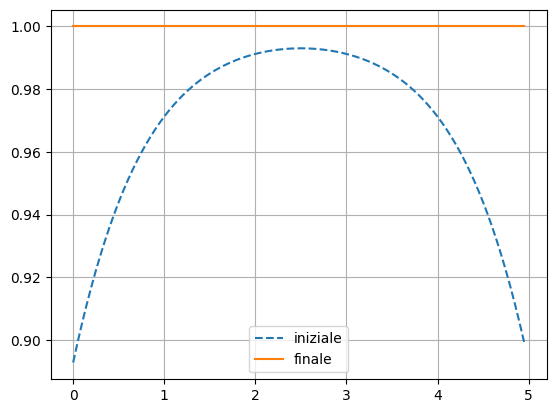

In [4]:
#Imposing initial conditions
x=np.linspace(0,L,Nx,endpoint=False)
U_curr=U_o(x)

#Solver

tol=1e-8 #the best pratice is to make Newton's method more accurate then the Euler
max_newton_iter=10

for n in range(T):
    U_prev = U_curr.copy()
    for k in range(max_newton_iter):
        delta = spsolve(J(U_curr), -G(U_curr, U_prev))
        U_curr += delta
        if np.linalg.norm(delta) < tol:
            break


# Plot the stationary state
plt.figure()
plt.plot(x, U_o(x), '--', label='iniziale')
plt.plot(x, U_curr, label='finale')
plt.legend()
plt.grid()
plt.show()


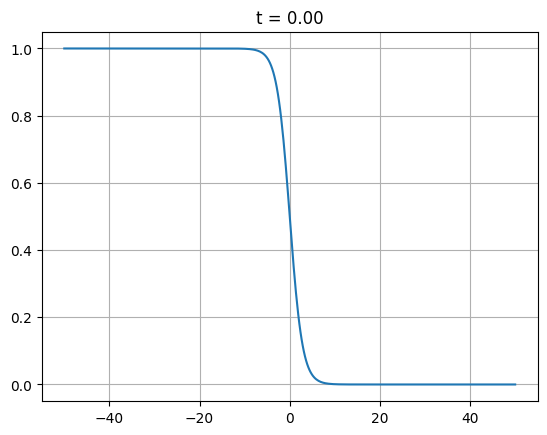

In [5]:
D = 1.0
v = 0.2
L = 100
Nx = 400

x = np.linspace(-L/2, L/2, Nx)

def u_profile(x, t):
    return 0.5 * (1 - np.tanh((x - v*t) / (2*np.sqrt(2*D))))

plt.ion()
fig, ax = plt.subplots()
line, = ax.plot(x, u_profile(x, 0))
ax.set_ylim(-0.05, 1.05)
ax.grid()

for t in np.linspace(0, 80, 200):
    line.set_ydata(u_profile(x, t))
    ax.set_title(f"t = {t:.2f}")
    plt.pause(0.05)

plt.ioff()
plt.show()


### Failing 1D $f\neq0$



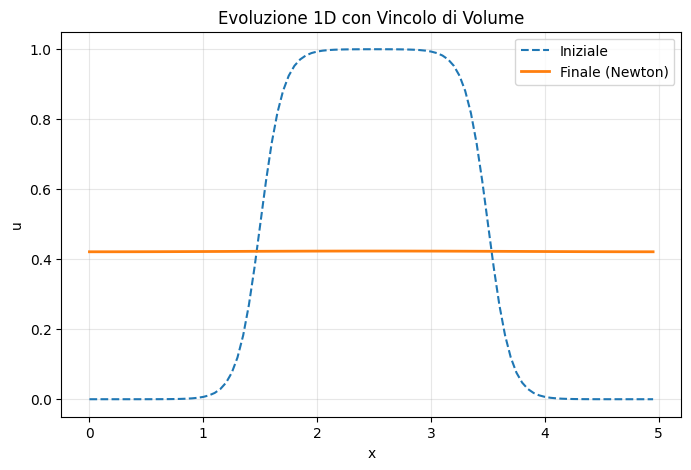

In [7]:
# --- 1. Parametri di simulazione ---
Nx = 100
L = 5.0
dx = L / Nx
dt = 0.1 # Newton è stabile, possiamo osare un dt più grande
T = 50

# Parametri modello
alpha_o = 1.0
V_o = 2.0  # Volume (lunghezza in 1D) target

# --- 2. Costruzione Matrici (Solo 1D) ---
main = -2.0 * np.ones(Nx) / dx**2
off  = 1.0 * np.ones(Nx-1) / dx**2

# Costruiamo senza forzare lo shape se le diagonali sono già corrette
A = diags([off, main, off], [-1, 0, 1], format='lil')
# BC Periodiche
A[0, -1] = 1/dx**2
A[-1, 0] = 1/dx**2
A = A.tocsr()

I = eye(Nx, format='csr')

# --- 3. Funzioni del Modello ---
def h(U):
    return (U**2)*(3-2*U)

def v(U):
    return np.sum(h(U)) * dx

def f_o(U):
    return alpha_o * (V_o - v(U))

def G(U, U_prev):
    f = f_o(U)
    reaction = U * (1 - U) * (U - 0.5 + f)
    # F(U) = (U - U_prev)/dt - [A@U + reaction] = 0
    # Moltiplichiamo tutto per dt per coerenza con lo Jacobiano
    return (I - dt * A) @ U - dt * reaction - U_prev

def J(U):
    f = f_o(U)
    # Derivata di u(1-u)(u-0.5+f) rispetto a u
    g = (1 - 2*U)*(U - 0.5 + f) + U*(1 - U)
    return (I - dt * A) - dt * diags(g, 0, format='csr')

def U_o(x):
    # Una tanh centrata e morbida
    return 0.5 * (1 - np.tanh((np.abs(x - L/2) - V_o/2) / 0.2))

# --- 4. Solver ---
x = np.linspace(0, L, Nx, endpoint=False)
U_curr = U_o(x)
tol = 1e-8
max_newton_iter = 15

for n in range(T):
    U_prev = U_curr.copy()
    for k in range(max_newton_iter):
        res = G(U_curr, U_prev)
        jac = J(U_curr)

        delta = spsolve(jac, -res)
        U_curr += delta

        if np.linalg.norm(delta) < tol:
            break

# --- 5. Plot ---
plt.figure(figsize=(8, 5))
plt.plot(x, U_o(x), '--', label='Iniziale')
plt.plot(x, U_curr, label='Finale (Newton)', linewidth=2)
plt.title("Evoluzione 1D con Vincolo di Volume")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

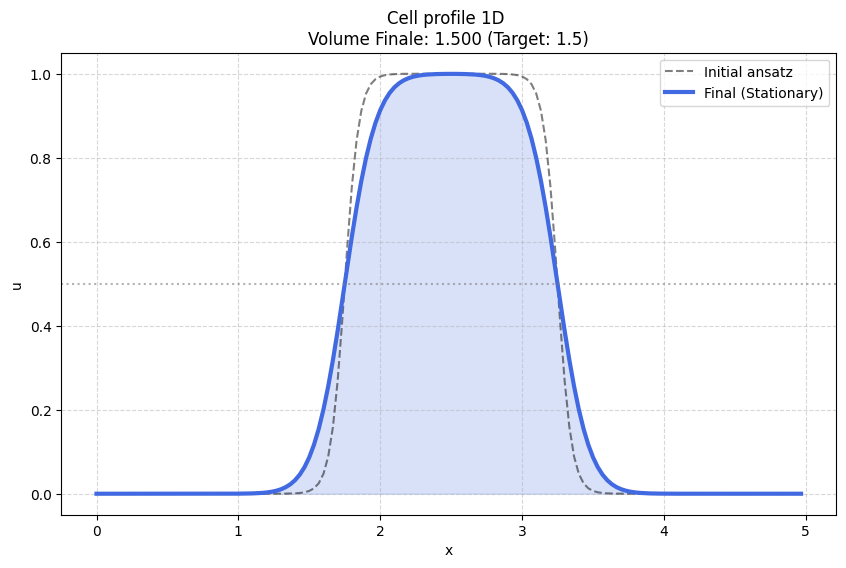

In [8]:
# --- 1. Parametri di simulazione ---
Nx = 150 # more resolution
L = 5.0
dx = L / Nx
dt = 0.01 # small dt to boost convergence in newton method
T = 200
D = 0.01

# Parametri modello
alpha_o = 2.0
V_o = 1.5  # Lunghezza target della cellula

# --- 2. Costruzione Matrici 1D ---
main = -2.0 * np.ones(Nx) / dx**2
off  = 1.0 * np.ones(Nx-1) / dx**2
A = diags([off, main, off], [-1, 0, 1], format='csr') # Matrice Laplaciana

I = eye(Nx, format='csr')

# --- 3. Funzioni del Modello ---
def h(U):
    return (U**2)*(3-2*U)

def v(U):
    return np.sum(h(U)) * dx

def f_o(U):
    return alpha_o * (V_o - v(U))

# --- 4. Inizializzazione ---
x = np.linspace(0, L, Nx, endpoint=False)
x1 = L/2 - V_o/2
x2 = L/2 + V_o/2
eps = 3 * dx # Interfaccia leggermente più larga per stabilità iniziale
U_curr = 0.5 * (np.tanh((x - x1)/eps) - np.tanh((x - x2)/eps))
U_init = U_curr.copy()

# --- 5. Solver Newton ---
tol = 1e-8
max_newton_iter = 20

for n in range(T):
    U_prev = U_curr.copy()
    for k in range(max_newton_iter):
        f = f_o(U_curr)

        # Reazione: u*(1-u)*(u - 0.5 + f)

        reaction = U_curr * (1 - U_curr) * (U_curr - 0.5 + f)

        # Residuo G(U) = (U - U_prev) - dt*(D*A@U + reaction)
        res = (I - dt * D * A) @ U_curr - dt * reaction - U_prev

        # Jacobiano J = I - dt*D*A - dt*diag(reaction')
        g = (1 - 2*U_curr)*(U_curr - 0.5 + f) + U_curr*(1 - U_curr)
        jac = (I - dt * D * A) - dt * diags(g, 0, format='csr')

        delta = spsolve(jac, -res)
        U_curr += delta

        if np.linalg.norm(delta) < tol:
            break

    U_curr = np.clip(U_curr, 0, 1)

# --- 6. Plot ---
plt.figure(figsize=(10, 6))
plt.plot(x, U_init, 'k--', alpha=0.5, label='Initial ansatz')
plt.plot(x, U_curr, color='royalblue', linewidth=3, label='Final (Stationary)')
plt.fill_between(x, U_curr, color='royalblue', alpha=0.2)
plt.axhline(0.5, color='gray', linestyle=':', alpha=0.6)
plt.title(f"Cell profile 1D \nVolume Finale: {v(U_curr):.3f} (Target: {V_o})")
plt.xlabel("x")
plt.ylabel("u")
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.show()

## Second failed attempt: foggy cell

In [9]:
#Building the laplacian 2D through by blocks A=tridiag(E,D,E)

def block_D(Nx, dx):
    main  =  4.0 * np.ones(Nx) / dx**2
    off   = -1.0 * np.ones(Nx-1) / dx**2

    D = diags([off, main, off], [-1, 0, 1], format='lil')

    # imposing periodic BC
    D[0, -1] = -1.0 / dx**2
    D[-1, 0] = -1.0 / dx**2

    return D

def block_E(Nx, dx):
    return diags([-1.0 * np.ones(Nx) / dx**2], [0], format='lil')

def laplacian(Nx, Ny, dx):
    D = block_D(Nx, dx)
    E = block_E(Nx, dx)

    A = lil_matrix((Nx*Ny, Nx*Ny))

    for j in range(Ny):
        row = slice(j*Nx, (j+1)*Nx)

        # blocco diagonale
        A[row, row] = D

        # blocco sopra
        if j < Ny-1:
            A[row, slice((j+1)*Nx, (j+2)*Nx)] = E

        # blocco sotto
        if j > 0:
            A[row, slice((j-1)*Nx, j*Nx)] = E

    # condizioni periodiche in y
    A[0:Nx, (Ny-1)*Nx:Ny*Nx] = E
    A[(Ny-1)*Nx:Ny*Nx, 0:Nx] = E

    return A.tocsr()

A = -laplacian(Nx, Ny, dx)


#Checking the correct implementation of the sparse laplacian 2D
#u = np.ones(Nx*Ny)
#print("||A u|| =", np.linalg.norm(A @ u))



# With constraint
alpha_o=0.05
V_o=8
omega=L*L #dimension of the simulation box

#The following functions work with np.array as inputs
#The following functions act on each element of the array U, so their functional form don't change passing from
#U[], vector of x points, to U[][] matrix of (x,y) grid points, since U is in a natural ordering vector form

def h(U):
    return (U**2)*(3-2*U)

def v(U): #computing the volume of the cell
    return np.sum(h(U))*dx*dy # O(dx) precision, approximation of the integral as a sum of bins using midpoint rule

def f_o(U):
    return alpha_o*(V_o-v(U))

I = identity(A.shape[0], format='csr')

def G(U, U_prev):
    f = f_o(U)
    return (I - dt*A) @ U \
           - dt*U*(1-U)*(U - 0.5 + f) \
           - U_prev

def J(U):
    f = f_o(U)
    g = (1 - U)*(U - 0.5 + f) \
        - U*(U - 0.5 + f) \
        + (1 - U)
    #print("dim U:", U.shape)
    #print("dim g:", g.shape)
    #print("dim I:", I.shape)
    #print("dim A:", A.shape)

    return (I - dt*A) - dt*diags(g, 0)

#Defining the initial condition

def init_circle(Nx, Ny, L, x0, y0, R, eps):
    x = np.linspace(0, L, Nx, endpoint=False)
    y = np.linspace(0, L, Ny, endpoint=False)
    X, Y = np.meshgrid(x, y)           # shape (Ny, Nx)
    r = np.sqrt((X - x0)**2 + (Y - y0)**2)
    U2D = 0.5 * (1.0 - np.tanh((r - R) / eps))
    return U2D  # shape (Ny, Nx)
def U_o():
    x0=L/2
    y0=L/2
    R=L/3.5
    eps=2*dx
    return init_circle(Nx, Ny, L, x0, y0, R, eps).flatten()



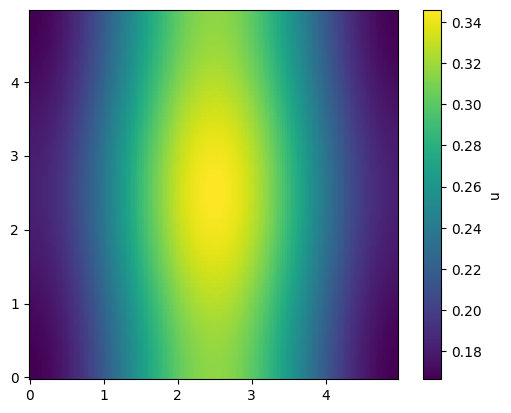

In [10]:
#Imposing initial conditions
#Natural ordering: i=k-int(np.floor(k/Nx))    ;    j=1+int(np.floor(k/Nx))
#The natural ordering is automatically imposed by .flatter in U_o's definition

T=100
U_curr=U_o()

#Solver

tol=1e-8 #the best pratice is to make Newton's method more accurate then the Euler
max_newton_iter=10

for n in range(T):
    U_prev = U_curr.copy()
    for k in range(max_newton_iter):

        delta = spsolve(J(U_curr), -G(U_curr, U_prev))

        U_curr += delta
        if np.linalg.norm(delta) < tol:
            break

from mpl_toolkits.mplot3d import Axes3D
# Plot the stationary state
U2D=U_curr.reshape((Ny, Nx)) #from natural ordering to 2D matrix
x = np.linspace(0, L, Nx, endpoint=False)
y = np.linspace(0, L, Ny, endpoint=False)
X, Y = np.meshgrid(x, y)
plt.figure()
plt.pcolormesh(X, Y, U2D, shading='auto')
plt.colorbar(label='u')
plt.gca().set_aspect('equal')
plt.show()


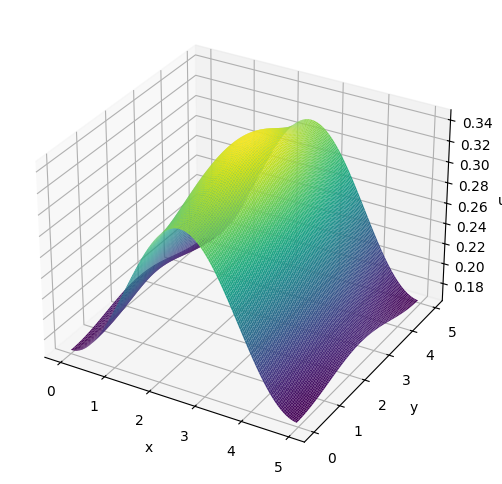

In [11]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, U2D, rstride=1, cstride=1, cmap='viridis', edgecolor='none')
ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_zlabel('u')
plt.show()

### Small improvement: Two cells of the same type

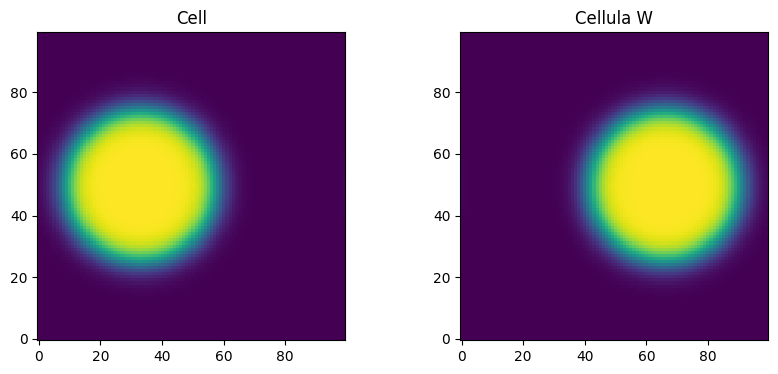

In [ ]:

# --- Parametri della griglia ---
Nx = Ny = 100
L = 5
dx = L / Nx  # Chiamiamolo dx per non confonderlo con la funzione h
dt = 0.01 * (dx**2 / 4)
steps = 1000

# Parametri modello
beta = 0.5
alpha_o = 1.0 # Assicurati che siano definiti
V_o = 1    # Valore target del volume

# --- Funzioni del Modello ---
def h_func(U): # Rinominata per evitare conflitti
    return (U**2)*(3-2*U)

def v_vol(U):
    # U è un vettore flat, h_func(U) pure
    return np.sum(h_func(U)) * (dx**2)

def f_o(U):
    return alpha_o * (V_o - v_vol(U))

# --- Costruzione Laplaciano (Matrice Sparsa) ---
def build_laplacian_matrix(Nx, Ny, dx):
    # Diagonale principale: -4 (per il laplaciano standard)
    # Off-diagonals: 1
    main = -4.0 * np.ones(Nx) / dx**2
    off  = 1.0 * np.ones(Nx-1) / dx**2
    D = diags([off, main, off], [-1, 0, 1], format='lil')

    # BC Periodiche orizzontali
    D[0, -1] = 1.0 / dx**2
    D[-1, 0] = 1.0 / dx**2

    E = diags([1.0 * np.ones(Nx) / dx**2], [0], format='lil')
    A = lil_matrix((Nx*Ny, Nx*Ny))

    for j in range(Ny):
        row = slice(j*Nx, (j+1)*Nx)
        A[row, row] = D
        # Connessioni verticali
        A[row, slice(((j+1)%Ny)*Nx, ((j+1)%Ny+1)*Nx)] = E
        A[row, slice(((j-1)%Ny)*Nx, ((j-1)%Ny+1)*Nx)] = E

    return A.tocsr()

A = build_laplacian_matrix(Nx, Ny, dx)

# --- Inizializzazione ---
# Nota: assicurati che init_circle restituisca un array 2D (Nx, Ny)
def init_circle(Nx, Ny, L, x0, y0, R, width):
    x = np.linspace(0, L, Nx)
    y = np.linspace(0, L, Ny)
    X, Y = np.meshgrid(x, y)
    dist = np.sqrt((X-x0)**2 + (Y-y0)**2)
    return 0.5 * (1 - np.tanh((dist - R) / width))

U = init_circle(Nx, Ny, L, L/3, L/2, L/4, 0.2).flatten()
W = init_circle(Nx, Ny, L, 2*L/3, L/2, L/4, 0.2).flatten()

# --- Loop Temporale ---
for s in range(steps):
    # Calcolo Laplaciano (A è già Delta)
    LapU = A @ U
    LapW = A @ W

    # Termini di reazione
    # Nota: f_o(U) restituisce uno scalare (forza globale di volume)
    force_u = f_o(U)
    force_w = f_o(W)

    dU = LapU - U*(1-U)*(U - 0.5 + force_u) - beta*U*h_func(W)
    dW = LapW - W*(1-W)*(W - 0.5 + force_w) - beta*W*h_func(U)

    # Aggiornamento (Eulero)
    U += dt * dU
    W += dt * dW

# --- Visualizzazione ---
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(U.reshape(Nx, Nx)*(1/25), origin='lower')
plt.title("Cell")
plt.subplot(1, 2, 2)
plt.imshow(W.reshape(Nx, Ny), origin='lower')
plt.title("Cellula W")
plt.show()
# plt.savefig("phase field model.png", dpi=300, bbox_inches='tight')


<Figure size 640x480 with 0 Axes>

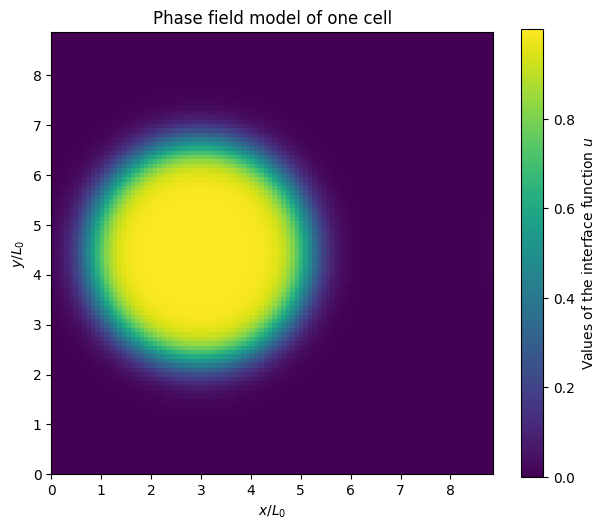

In [ ]:
"""
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(
    U.reshape(Nx, Ny),
    origin='lower',
    extent=[0, L, 0, L],
    cmap='viridis'
)
plt.colorbar(label='u')
plt.title("Cell")
plt.xlabel(r"$x/L_0$")
plt.ylabel(r"$y/L_0$")
plt.xticks([1,2,3,4,5])
plt.yticks([1,2,3,4,5])

plt.subplot(1, 2, 2)
plt.imshow(
    W.reshape(Nx, Ny),
    origin='lower',
    extent=[0, L, 0, L],
    cmap='viridis'
)
plt.colorbar(label='w')
plt.title("Cellula W")
plt.xlabel(r"$x/L_0$")
plt.ylabel(r"$y/L_0$")
plt.xticks([1,2,3,4,5])
plt.yticks([1,2,3,4,5])

plt.tight_layout()
plt.savefig("phase field model.png", dpi=300, bbox_inches='tight')
plt.show()

"""

# --- Sotto i tuoi parametri ---
L0 = np.sqrt(V_o / np.pi)  # Raggio della cellula a riposo
# --- Nella sezione Visualizzazione ---
x_adim = np.linspace(0, L, Nx) / L0
y_adim = np.linspace(0, L, Ny) / L0
# --- Visualizzazione Rinormalizzata ---
plt.figure(figsize=(12, 5))

# Definiamo i limiti del grafico: [x_min, x_max, y_min, y_max]
ext = [x_adim[0], x_adim[-1], y_adim[0], y_adim[-1]]

plt.subplot(1, 2, 1)
# Usiamo extent per rinormalizzare gli assi
plt.imshow(U.reshape(Nx, Ny), origin='lower', extent=ext, cmap='viridis')
plt.colorbar(label="Values of the interface function $u$")
plt.xlabel(r"$x / L_0$")
plt.ylabel(r"$y / L_0$")
plt.title("Phase field model of one cell")

"""
plt.subplot(1, 2, 2)
plt.imshow(W.reshape(Nx, Ny), origin='lower', extent=ext, cmap='magma')
plt.colorbar(label="Campo d'ordine $w$")
plt.xlabel(r"$x / L_0$")
plt.ylabel(r"$y / L_0$")
plt.title("Cellula W (Adimensionale)")
"""
# plt.savefig("phase field model.png", bbox_inches='tight')
plt.tight_layout()
plt.show()

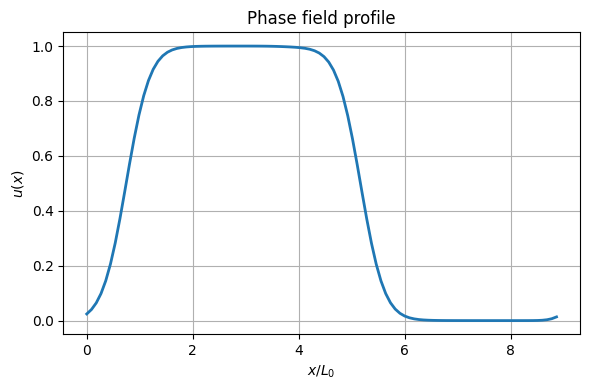

In [ ]:
# --- Parametri ---
Nx = Ny = 100
L = 5.0
x = np.linspace(0, L, Nx) /L0

# U = tuo campo flatten (Nx*Ny,)
U2D = U.reshape(Ny, Nx)   # attenzione: (y,x)

# --- Estrazione profilo centrale ---
j_center = Ny // 2        # sezione orizzontale al centro
u_profile = U2D[j_center, :]

# --- Plot ---
plt.figure(figsize=(6,4))
plt.plot(x, u_profile, lw=2)
plt.xlabel(r"$x/L_0$")
plt.ylabel(r"$u(x)$")
plt.title("Phase field profile")
plt.grid(True)

# --- Salvataggio ---
plt.tight_layout()
# plt.savefig("double_sigmoid_profile.png", dpi=300, bbox_inches="tight")
plt.show()


# Simulation od Adhesion

## Two cells

c:\Users\Valeria Bidolli\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


Step 0: VolU=0.248, VolW=0.248
Step 1000: VolU=0.760, VolW=0.760
Step 2000: VolU=0.907, VolW=0.907
Step 3000: VolU=0.921, VolW=0.921
Step 4000: VolU=0.923, VolW=0.923
Step 5000: VolU=0.923, VolW=0.923
Step 6000: VolU=0.923, VolW=0.923
Step 7000: VolU=0.923, VolW=0.923
Step 8000: VolU=0.923, VolW=0.923
Step 9000: VolU=0.923, VolW=0.923
Step 10000: VolU=0.923, VolW=0.923
Step 11000: VolU=0.923, VolW=0.923
Step 12000: VolU=0.923, VolW=0.923
Step 13000: VolU=0.923, VolW=0.923
Step 14000: VolU=0.923, VolW=0.923
Step 15000: VolU=0.923, VolW=0.923
Step 16000: VolU=0.923, VolW=0.923
Step 17000: VolU=0.923, VolW=0.923
Step 18000: VolU=0.923, VolW=0.923
Step 19000: VolU=0.923, VolW=0.923


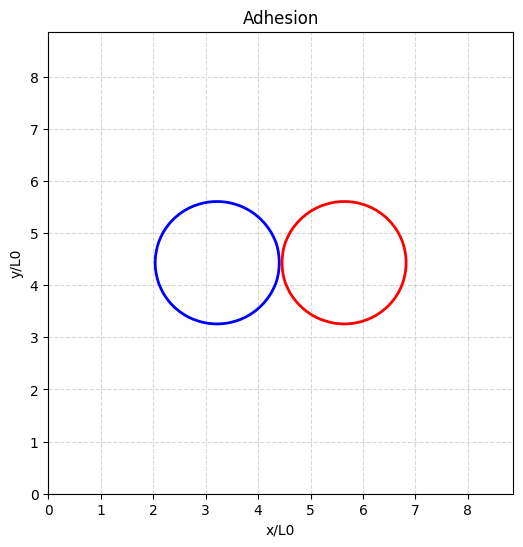

In [ ]:
from scipy.sparse import diags, kron, csr_matrix

# Parameters as in Nomiura's fifth figure
N = 100
L_dom = 5.0
dx = 0.05
dt = 0.01
steps = 20000  # To plot the function after a long wait

D = 0.001      # Diffusion coefficient
V_target = 1.0 #  target volume
alpha = 1.0      # alpha in the article
beta = 1.0     # Parameter of the excluded volume
gamma = 0.01   # Superficial tension
eta = 0.003   # Adhesion (0.0, 0.003, o 0.0065 come in Fig 5)

def h_func(u):
    return u**2 * (3 - 2*u)

# Building yhe 2D Laplacian (N^2 x N^2)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)

# Inizializaztion
x = np.linspace(0, L_dom, N)/L0
X, Y = np.meshgrid(x, x)
# Centeres positions: a 2.5 +/- 0.7 (total distance 1.4)
u_init = 0.5 * (1 - np.tanh((np.sqrt((X-1.8/L0)**2 + (Y-2.5/L0)**2) - 0.5) / 0.1))
w_init = 0.5 * (1 - np.tanh((np.sqrt((X-3.2/L0)**2 + (Y-2.5/L0)**2) - 0.5) / 0.1))

U = u_init.flatten()
W = w_init.flatten()

# This is the time loop
for s in range(steps):

    hU, hW = h_func(U), h_func(W) #computing functions h of the two cells U,W

    # Computing volume using a Rienmann' sum approximation
    volU = np.sum(hU) * (dx**2)
    volW = np.sum(hW) * (dx**2)

    # Computing the laplacians of the cells' functions
    lap_hU = Lap @ hU
    lap_hW = Lap @ hW

    # Reaction term: (f = alpha*(V_target - vol) - beta*h_altra)
    # Interface terms: eta*lap_hW e gamma*lap_hU
    reac_U = (U - 0.5 + alpha*(V_target - volU) - beta*hW + eta*lap_hW + gamma*lap_hU)
    reac_W = (W - 0.5 + alpha*(V_target - volW) - beta*hU + eta*lap_hU + gamma*lap_hW)

    # Coupled equations
    dU = D*(Lap @ U) + U*(1-U)*reac_U
    dW = D*(Lap @ W) + W*(1-W)*reac_W

    # Update
    U += dt * dU
    W += dt * dW

    if s % 1000 == 0:
        print(f"Step {s}: VolU={volU:.3f}, VolW={volW:.3f}")

# Contour plot at u=0.2 as in figure 5
plt.figure(figsize=(6,6))
plt.contour(X, Y, U.reshape(N,N), levels=[0.2], colors='blue', linewidths=2)
plt.contour(X, Y, W.reshape(N,N), levels=[0.2], colors='red', linewidths=2)
plt.title(f"Adhesion")
plt.xlabel("x/L0")
plt.ylabel("y/L0")
plt.grid(True, linestyle='--', alpha=0.5)
# plt.savefig("adhesion.png", dpi=300, bbox_inches='tight')

plt.show()

## Two cells Coming close

In [16]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


# Parameters as in Nomiura's fifth figure
N = 100
L_dom = 5.0
dx = 0.05
dt = 0.01
D = 0.001      # Diffusion coefficient
V_target = 1.0 #  target volume
alpha = 1.0      # alpha in the article
beta = 1.0     # Parameter of the excluded volume
gamma = 0.01   # Superficial tension
eta = 0.0065   # Adhesion (0.0, 0.003, o 0.0065 come in Fig 5)
steps = 20000  # To plot the function after a long wait


def h_func(u): return u**2 * (3 - 2*u)

# Building yhe 2D Laplacian (N^2 x N^2)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)

#Inizialization: x = np.linspace(0, L_dom, N)/L0
X, Y = np.meshgrid(x, x)
U = (0.5 * (1 - np.tanh((np.sqrt((X-1.8/L0)**2 + (Y-2.5/L0)**2) - 0.5) / 0.1))).flatten()
W = (0.5 * (1 - np.tanh((np.sqrt((X-3.2/L0)**2 + (Y-2.5/L0)**2) - 0.5) / 0.1))).flatten()

#Setting up for the animation fig, ax = plt.subplots(figsize=(5, 5))
# Using contourf for a browser-like rendering
cont = ax.contourf(X, Y, (U + 2*W).reshape(N, N), levels=20, cmap='RdBu_r')
ax.set_aspect('equal')

def update(frame):
    global U, W
    # 150 physical steps for each animation step
    for _ in range(150):
        hU, hW = h_func(U), h_func(W)
        volU, volW = np.sum(hU)*(dx**2), np.sum(hW)*(dx**2)
        lap_hU, lap_hW = Lap @ hU, Lap @ hW

        reac_U = (U - 0.5 + alpha*(V_target - volU) - beta*hW + eta*lap_hW + gamma*lap_hU)
        reac_W = (W - 0.5 + alpha*(V_target - volW) - beta*hU + eta*lap_hU + gamma*lap_hW)

        U += dt * (D*(Lap @ U) + U*(1-U)*reac_U)
        W += dt * (D*(Lap @ W) + W*(1-W)*reac_W)

    ax.clear()
    ax.contour(X, Y, U.reshape(N,N), levels=[0.2], colors='blue')
    ax.contour(X, Y, W.reshape(N,N), levels=[0.2], colors='red')
    ax.set_title(f"Simulation - Frame {frame}")
    ax.grid()
    return ax,

# Generiamo l'animazione (es. 60 frame)
ani = FuncAnimation(fig, update, frames=60, blit=False)

# IL TRUCCO PER IL BROWSER:
plt.close() # Non mostrare l'immagine statica
HTML(ani.to_jshtml()) # Genera il player Javascript

### Baricentrs

In [17]:
#Parameters
N = 100
L_dom = 5.0
dx = 0.05
dt = 0.01
D = 0.001
V_target = 1.0
alpha = 1.0
beta = 1.0
gamma = 0.01
eta = 0.0065

# Scale
L0 = np.sqrt(V_target / np.pi)

def h_func(u): return u**2 * (3 - 2*u)


# Building yhe 2D Laplacian (N^2 x N^2)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)

# Inizialization - physical coordinates
x_vec = np.linspace(0, L_dom, N)
X, Y = np.meshgrid(x_vec, x_vec)
U = (0.5 * (1 - np.tanh((np.sqrt((X-1.8)**2 + (Y-2.5)**2) - L0) / 0.1))).flatten()
W = (0.5 * (1 - np.tanh((np.sqrt((X-3.2)**2 + (Y-2.5)**2) - L0) / 0.1))).flatten()

fig, ax = plt.subplots(figsize=(5, 5))

def update(frame):
    global U, W
    for _ in range(150):
        hU, hW = h_func(U), h_func(W)
        volU, volW = np.sum(hU)*(dx**2), np.sum(hW)*(dx**2)
        lap_hU, lap_hW = Lap @ hU, Lap @ hW

        reac_U = (U - 0.5 + alpha*(V_target - volU) - beta*hW + eta*lap_hW + gamma*lap_hU)
        reac_W = (W - 0.5 + alpha*(V_target - volW) - beta*hU + eta*lap_hU + gamma*lap_hW)

        U += dt * (D*(Lap @ U) + U*(1-U)*reac_U)
        W += dt * (D*(Lap @ W) + W*(1-W)*reac_W)

        U = np.clip(U, 0, 1)
        W = np.clip(W, 0, 1)

    ax.clear()
    # Adimensional visualization
    X_adim, Y_adim = X/L0, Y/L0

    # 1. Contour plots
    ax.contour(X_adim, Y_adim, U.reshape(N,N), levels=[0.5], colors='blue', linewidths=2)
    ax.contour(X_adim, Y_adim, W.reshape(N,N), levels=[0.5], colors='red', linewidths=2)

    # 2. Adimensional centers of mass
    hU_2d, hW_2d = h_func(U).reshape(N,N), h_func(W).reshape(N,N)
    sum_hU, sum_hW = np.sum(hU_2d), np.sum(hW_2d)

    # cx, cy
    cx_u, cy_u = np.sum(X_adim * hU_2d)/sum_hU, np.sum(Y_adim * hU_2d)/sum_hU
    cx_w, cy_w = np.sum(X_adim * hW_2d)/sum_hW, np.sum(Y_adim * hW_2d)/sum_hW

    ax.scatter(cx_u, cy_u, color='blue', marker='x', s=100, zorder=5)
    ax.scatter(cx_w, cy_w, color='red', marker='x', s=100, zorder=5)

    # 3. adimensional distance
    distanza = np.sqrt((cx_u - cx_w)**2 + (cy_u - cy_w)**2)
    ax.plot([cx_u, cx_w], [cy_u, cy_w], 'k--', alpha=0.3, zorder=1)

    ax.text((cx_u + cx_w)/2, (cy_u + cy_w)/2 + 0.2, f"d = {distanza:.2f}",
            fontsize=11, fontweight='bold', ha='center', color='darkgreen',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    ax.set_aspect('equal')
    ax.set_xlim(0, L_dom/L0)
    ax.set_ylim(0, L_dom/L0)
    ax.set_xlabel(r"$x / L_0$")
    ax.set_ylabel(r"$y / L_0$")
    ax.set_title(f"Following centers (Adimensional) - Frame {frame}")
    ax.grid(True, linestyle=':', alpha=0.6)
    return ax,

ani = FuncAnimation(fig, update, frames=60, interval=100, blit=False)
plt.close()
HTML(ani.to_jshtml())

c:\Users\Valeria Bidolli\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


### Contour plots of e_eta and u(centers,t)

c:\Users\Valeria Bidolli\AppData\Local\Programs\Python\Python311\Lib\site-packages\scipy\sparse\_index.py:174: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_intXint(row, col, x.flat[0])


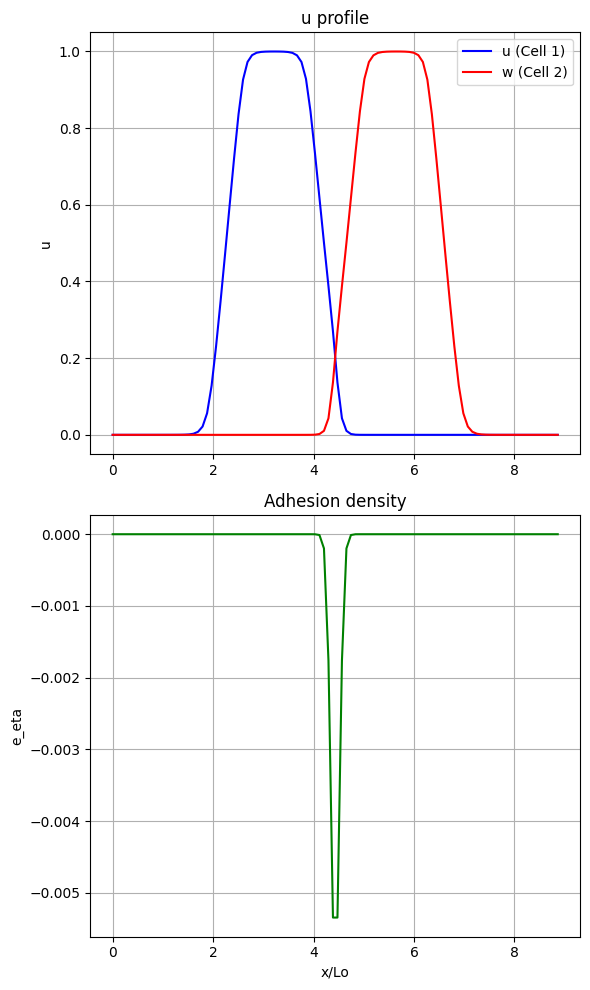

In [ ]:
# Parameters (Fig. 5C: high adhesion)
N = 100
L_dom = 5.0
dx = 0.05
dt = 0.01
D = 0.001
V_target = 1.0
alpha = 1.0
beta = 1.0
gamma = 0.01
eta = 0.0065

def h_func(u): return u**2 * (3 - 2*u)
def grad_h(u): return 6 * u * (1 - u) #computing the gradient

# Building yhe 2D Laplacian (N^2 x N^2)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)

# Inizialization (Distance 1.4 as in the paper)
x = np.linspace(0, L_dom, N)/L0
X, Y = np.meshgrid(x, x)
mid_y = N // 2 # dotted line

U = (0.5 * (1 - np.tanh((np.sqrt((X-1.8/L0)**2 + (Y-2.5/L0)**2) - 0.5/L0) / 0.1))).flatten()
W = (0.5 * (1 - np.tanh((np.sqrt((X-3.2/L0)**2 + (Y-2.5/L0)**2) - 0.5/L0) / 0.1))).flatten()

# Simulation (aiming at the stationary state)
for s in range(5000):
    hU, hW = h_func(U), h_func(W)
    volU, volW = np.sum(hU)*(dx**2), np.sum(hW)*(dx**2)
    lap_hU, lap_hW = Lap @ hU, Lap @ hW
    reac_U = (U - 0.5 + alpha*(V_target - volU) - beta*hW + eta*lap_hW + gamma*lap_hU)
    reac_W = (W - 0.5 + alpha*(V_target - volW) - beta*hU + eta*lap_hU + gamma*lap_hW)
    U += dt * (D*(Lap @ U) + U*(1-U)*reac_U)
    W += dt * (D*(Lap @ W) + W*(1-W)*reac_W)

# Computing e_eta
# Computing gradients
U_2d, W_2d = U.reshape(N, N), W.reshape(N, N)
grad_hU_x, grad_hU_y = np.gradient(h_func(U_2d), dx)
grad_hW_x, grad_hW_y = np.gradient(h_func(W_2d), dx)
e_eta = (eta / 6.0) * (grad_hU_x * grad_hW_x + grad_hU_y * grad_hW_y)

# Final graphs
fig, (ax2, ax3) = plt.subplots(2, 1, figsize=(6, 10))


# 2. u profile along y=2.5 (dotted line i.e. the center)
ax2.plot(x, U_2d[mid_y, :], 'b', label='u (Cell 1)')
ax2.plot(x, W_2d[mid_y, :], 'r', label='w (Cell 2)')
ax2.set_ylabel("u")
ax2.set_title("u profile")
ax2.legend()
ax2.grid()
# 3. e_eta along y=2.5
ax3.plot(x, e_eta[mid_y, :], 'g')
ax3.set_ylabel("e_eta")
ax3.set_xlabel("x/Lo")
ax3.set_title("Adhesion density")
ax3.grid()
# plt.savefig("curves.png", dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

# Cell division

## Experiment with two cells

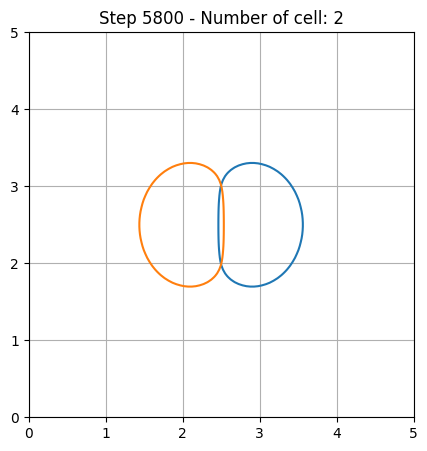

In [19]:

from IPython.display import display, clear_output

# Parameters like fig 4
N = 100 # number of grid points
L_dom = 5.0
dx = 0.05
dt = 0.02
# model parameters
D = 0.001
alpha = 1.0
gamma = 0.01
L0 = np.sqrt(V_target / np.pi)
T=6000 #Length of the simulation

# Useful functions
def h_func(u): return u**2 * (3 - 2*u)

#building the laplacian through a kronecker product
Lap = get_laplacian_2d(N, dx)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)


x_coord = np.linspace(0, L_dom, N)
X, Y = np.meshgrid(x_coord, x_coord)

# This is the initial condition of one cell
U = (0.5 * (1 - np.tanh((np.sqrt((X-2.5)**2 + (Y-2.5)**2) - 0.4) / 0.1))).flatten()
cells = [U] # This is a list and here I save the active cells
#Now cells[1] is a vector that contains the initial shape of the cell
V_targets = [0.75]
v_star = 1.5 # threshold: after the cell reaches this volume it splits in two doughters

fig, ax = plt.subplots(figsize=(5, 5)) #I prepare the figure to plot results and the animation

for s in range(T):
    new_cells = [] #lists' inizialization
    to_remove = []

    # For each existing cell:
    for i in range(len(cells)): #for each cell
        u = cells[i] #active cell, still a vector
        hU = h_func(u) #auxiliary variable I save the result of h(u) calling
        vol = np.sum(hU) * (dx**2) #Riemann' sum to approximate the integral leading to cell's volume

        # Linearly increasing cell's volume
        V_targets[i] += 0.0002 #this is inside the for cycle in s variable so I get a volume increase each s-step

        # Here I ensure that excluded volume condition is satisfied for each cell
        others_h = np.zeros_like(u) #returns an array of zeros with same shape of u
        for j, other in enumerate(cells):
            if i != j: others_h += h_func(other)

        # Solving the Allen-Cahn
        lap_hU = Lap @ hU
        reac = (u - 0.5 + alpha*(V_targets[i] - vol) - 1.0*others_h + gamma*lap_hU)
        cells[i] += dt * (D*(Lap @ u) + u*(1-u)*reac) #here I use dt but the time is advancing through s, so I advance of dt in the equation at each step

        # Cell splitting
        if vol > v_star: #checking the condition
            # I cut along one axis
            # Possible improvement: cutting along a random axis or a model-based one
            mask = 0.5 * (1 + np.tanh((X.flatten() - 2.5) / 0.1))
            new_cells.append(cells[i] * mask)    # Dougther cell 1
            new_cells.append(cells[i] * (1-mask)) # Dougther cell 2
            to_remove.append(i)

    # If a splitting occurred, the cell list must be updated
    if to_remove:
        for index in sorted(to_remove, reverse=True): #now vector to_remove is organized to allow the pop() function to be used
            cells.pop(index)
            V_targets.pop(index)
        for nc in new_cells:
            cells.append(nc)
            V_targets.append(0.8) # Volume reset for the doughters
    # Animation
    if s % 200 == 0:
        ax.clear()
        total_view = np.zeros((N, N))
        for idx, c in enumerate(cells):
            ax.contour(X, Y, c.reshape(N,N), levels=[0.2], colors=[plt.cm.tab10(idx%10)])

        ax.set_title(f"Step {s} - Number of cell: {len(cells)}")
        ax.set_aspect('equal')
        ax.grid()
        clear_output(wait=True)
        display(fig)

plt.close()

### Multicellular experiment

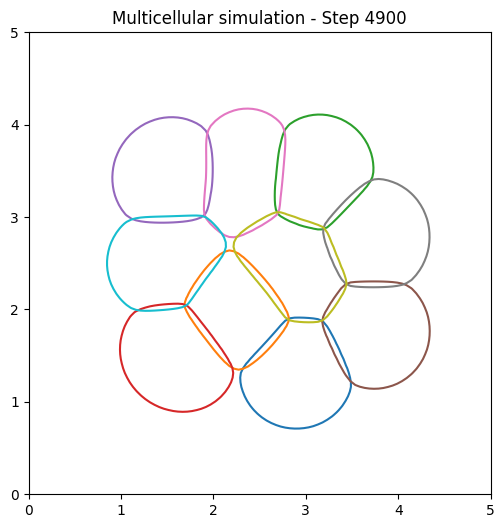

In [20]:
# Parameters like fig 4
N = 100 # number of grid points
L_dom = 5.0
dx = 0.05
dt = 0.02
# model parameters
D = 0.001
alpha = 1.0
beta=1.2 # excluded volume coefficient
gamma = 0.01# coefficient of surface tension
L0 = np.sqrt(V_target / np.pi) #cell's initial typical dimension




def h_func(u): return u**2 * (3 - 2*u)

#building the laplacian through a kronecker product
Lap = get_laplacian_2d(N, dx)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)


# Inizialization: 10 cells in random positions
num_cellule = 10
cells = []
V_targets = [0.8] * num_cellule

x_coord = np.linspace(0, L_dom, N)
X, Y = np.meshgrid(x_coord, x_coord)

for i in range(num_cellule):
    # Random positions at the center of the domain
    x0, y0 = np.random.uniform(1.5, 3.5), np.random.uniform(1.5, 3.5)
    u_init = (0.5 * (1 - np.tanh((np.sqrt((X-x0)**2 + (Y-y0)**2) - 0.4) / 0.1))).flatten()
    cells.append(u_init)

# Simulation loop
fig, ax = plt.subplots(figsize=(6, 6))

for s in range(5000):
    # Computing h(u) for each cell - this should save some time
    h_all = [h_func(c) for c in cells]
    sum_h = np.sum(h_all, axis=0) # Total simulation/grid space occupied by the multicellular structure

    for i in range(len(cells)):
        u = cells[i]
        h_i = h_all[i]
        vol_i = np.sum(h_i) * (dx**2)

        # Excluding volume computation: beta * (Somma di h_j con j != i)
        # obtained by:
        others_h = sum_h - h_i #the total h minus the contribution of the i one

        lap_u = Lap @ u
        lap_hi = Lap @ h_i

        # Simplified adhesion term:
        # Laplacian of "others" field
        lap_others_h = Lap @ others_h

        # Reaction term
        reac = (u - 0.5 + alpha*(V_targets[i] - vol_i) - beta*others_h +
                eta*lap_others_h + gamma*lap_hi)

        # Updating the dynamics
        cells[i] += dt * (D*lap_u + u*(1-u)*reac)

        # Ensuring numerical stability with a clamp
        cells[i] = np.clip(cells[i], 0, 1)

    # Visualization
    if s % 100 == 0:
        ax.clear()
        for idx, c in enumerate(cells):
            ax.contour(X, Y, c.reshape(N,N), levels=[0.2], colors=[plt.cm.tab10(idx%10)]) #selecting different colors

        ax.set_title(f"Multicellular simulation - Step {s}")
        ax.set_aspect('equal')
        clear_output(wait=True)
        display(fig)

plt.close()

## Final simulation

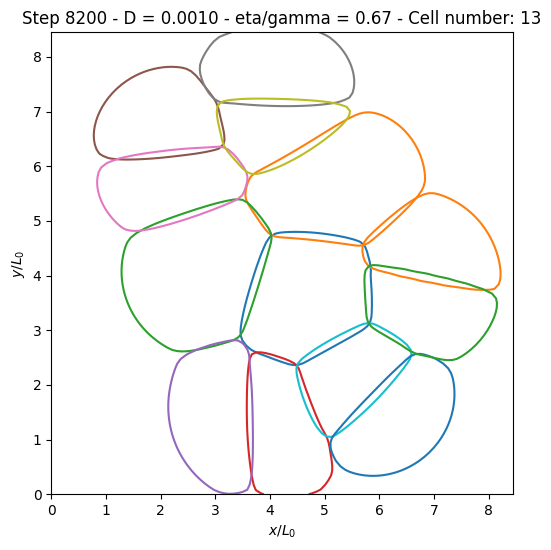

Ultimo frame salvato come 'final_frame.png'


In [ ]:
# Parameters like fig 4
N = 100 # number of grid points
L_dom = 5.0
dx = 0.05
dt = 0.02
# model parameters
D = 0.001
alpha = 1.0
beta= 3.5 # excluded volume coefficient
gamma = 0.06 # coefficient of surface tension
eta = 0.04 #Adhesion term
v_init = 0.7  # Volume of a daughter cell
v_star = 1.1 # Critical volume for a cell division
N_max_cells = 15 # Max number of cells in the grid
L0 = np.sqrt(v_star / np.pi) #cell's initial typical dimension

def h_func(u): return u**2 * (3 - 2*u)

#building the laplacian through a kronecker product
Lap = get_laplacian_2d(N, dx)
def get_laplacian_2d(N, dx):
    # 1D operator
    main = -2.0 * np.ones(N) / dx**2
    off = np.ones(N-1) / dx**2
    D1 = diags([off, main, off], [-1, 0, 1], shape=(N, N), format='csr')
    # Imposing periodic boundary conditions
    D1[0, -1] = 1.0 / dx**2
    D1[-1, 0] = 1.0 / dx**2

    I = diags([np.ones(N)], [0], shape=(N, N), format='csr')

    # Laplacian 2D with kronecker product!
    Lap2d = kron(I, D1) + kron(D1, I)
    return Lap2d

Lap = get_laplacian_2d(N, dx)

x_c = np.linspace(0, L_dom, N)
X, Y = np.meshgrid(x_c, x_c)

#Inizializing one cell
u0 = (0.5 * (1 - np.tanh((np.sqrt((X-2.5)**2 + (Y-2.5)**2) - 0.5) / 0.1))).flatten() #initial condition
cells = [u0]
V_targets = [v_init]

#Simulation loop
fig, ax = plt.subplots(figsize=(6, 6))

for s in range(15000):
    h_all = [h_func(c) for c in cells]
    sum_h = np.sum(h_all, axis=0)

    cells_to_add = []
    indices_to_remove = []

    for i in range(len(cells)):
        # Allen-Cahn
        u = cells[i]
        hi = h_all[i]
        vol_i = np.sum(hi) * (dx**2)

        # Linear increase of each cell's volume
        V_targets[i] += 0.0003

        others_h = sum_h - hi
        reac = (u - 0.5 + alpha*(V_targets[i] - vol_i) - beta*others_h +
                eta*(Lap @ others_h) + gamma*(Lap @ hi))

        cells[i] += dt * (D*(Lap @ u) + u*(1-u)*reac)
        cells[i] = np.clip(cells[i], 0, 1)

        # Division logic (simplified)
        if vol_i > v_star and len(cells) + len(cells_to_add) < N_max_cells:
            indices_to_remove.append(i)

            # Computing the center of mass
            u_2d = cells[i].reshape(N, N)
            m00 = np.sum(u_2d)
            cx = np.sum(X * u_2d) / m00
            cy = np.sum(Y * u_2d) / m00

            # Cut axis
            angle = np.random.uniform(0, np.pi) #random angle
            plane = (X - cx) * np.cos(angle) + (Y - cy) * np.sin(angle)
            mask = 0.5 * (1 + np.tanh(plane / 0.05)).flatten()

            cells_to_add.append(cells[i] * mask)
            cells_to_add.append(cells[i] * (1 - mask))

    # Updating the list of cells
    if indices_to_remove:
        for idx in sorted(indices_to_remove, reverse=True):
            cells.pop(idx)
            V_targets.pop(idx)
        for new_c in cells_to_add:
            cells.append(new_c)
            V_targets.append(v_init)

    # Visualization
    if s % 200 == 0:
        ax.clear()
        for idx, c in enumerate(cells):
            ax.contour(X/L0, Y/L0, c.reshape(N,N), levels=[0.2], colors=[plt.cm.tab10(idx%10)])
        ax.set_title(f"Step {s} - D = {D:.4f} - eta/gamma = {eta/gamma:.2f} - Cell number: {len(cells)}")
        ax.set_xlabel(r"$x / L_0$")
        ax.set_ylabel(r"$y / L_0$")
        ax.set_aspect('equal')
        clear_output(wait=True)
        display(fig)
        if len(cells) >= 10: break #

ax.clear()
for idx, c in enumerate(cells):
    ax.contour(X/L0, Y/L0, c.reshape(N,N), levels=[0.2], colors=[plt.cm.tab10(idx%10)])
ax.set_title(f"Step {s} - D = {D:.4f} - eta/gamma = {eta/gamma:.2f} - Cell number: {len(cells)}")
ax.set_xlabel(r"$x / L_0$")
ax.set_ylabel(r"$y / L_0$")
ax.set_aspect('equal')

# Saving last frame
# fig.savefig("final_frame.png", dpi=300, bbox_inches='tight')
print("Ultimo frame salvato come 'final_frame.png'")

plt.close()